# Validation
# Setup
Running this notebook demonstrates the capabilities of our models.

**In the validation_config.yaml change the "model" variable at the top for the model you wish to evaluate**

## Imports

In [27]:
#For some reason the adapterDETR model import breaks if you don't do it first
import sys
import os
#Set parent path to the root of the repo, to be able to import models
parent_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, parent_dir)
from model_code.adapterDETR import AdapterDetr
from validation.validation_functions import eval_model, show_image_prediction
from data.dataloader import get_dataloader

from hydra.utils import instantiate

In [28]:
from main import DetectionModel, get_loss_fn

## Config

In [29]:
from omegaconf import OmegaConf
config = OmegaConf.load("validation_config.yaml")

## Dataloader
The dataloader loads in both imagedata and their embeddings, both can be used

I also create a subset dataset to not pass all of it through the models

In [30]:
dataset, dataloader = get_dataloader(config, split="test")

import torch
from torch.utils.data import Subset, DataLoader
## TEMPORARY.
# Create a subset of the data to not overload memory
subset_dataset = torch.utils.data.Subset(dataloader.dataset, range(50))

Loaded 4535 samples from test split


## Model

In [31]:
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
device

'cuda'

In [32]:
criterion, weight_dict = get_loss_fn(config)

In [33]:
if config.model=='orgDETR':
    model = instantiate(config.org_detr)
    checkpoint_dir = config.train.checkpoint_dir
    resume_checkpoint_dir = config.train.resume_checkpoint_dir
    model = DetectionModel.load_from_checkpoint('.'+resume_checkpoint_dir, model=model, 
                                                criterion=criterion, weight_dict=weight_dict,
                                                config=config)
    print(f"Loading model from {checkpoint_dir}")
elif config.model=='adapter_detr':  
    model = instantiate(config.adapter_detr)
    checkpoint_dir = config.train.checkpoint_dir
    resume_checkpoint_dir = config.train.resume_checkpoint_dir
    checkpoint = torch.load("."+resume_checkpoint_dir, map_location=device)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"Loading model from {checkpoint_dir}")

INFO:timm.models._builder:Loading pretrained weights from Hugging Face hub (timm/resnet50.a1_in1k)
INFO:timm.models._hub:[timm/resnet50.a1_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.
INFO:timm.models._builder:Missing keys (fc.weight, fc.bias) discovered while loading pretrained weights. This is expected if model is being adapted.
Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. i

Loading model from ./outputs/train-freeze-backbone-num-queries-2


In [35]:
model.eval()

DetectionModel(
  (model): Detr(
    (detr): DetrForObjectDetection(
      (model): DetrModel(
        (backbone): DetrConvModel(
          (conv_encoder): DetrConvEncoder(
            (model): FeatureListNet(
              (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
              (bn1): DetrFrozenBatchNorm2d()
              (act1): ReLU(inplace=True)
              (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
              (layer1): Sequential(
                (0): Bottleneck(
                  (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
                  (bn1): DetrFrozenBatchNorm2d()
                  (act1): ReLU(inplace=True)
                  (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
                  (bn2): DetrFrozenBatchNorm2d()
                  (drop_block): Identity()
                  (act2): ReLU(inplace=True)
          

# Evaluation

## Quantitative

Note the parameter with_images. If the model you loaded in the last step expects images as input, then put it to True

In [36]:
avg_val_loss, evaluation_results = eval_model(config,model,dataset, 0.5, with_images=True)

100%|██████████████████████████████████████████████████████████████████████████████████████| 4535/4535 [03:23<00:00, 22.33it/s]


In [37]:
print(f"Average val loss: {avg_val_loss}")
print()
for metric in evaluation_results:
    print(metric + ": " + str(evaluation_results[metric]))

Average val loss: 2.6203856824399225

case1_gt_match_pred_class_box_overlap: 2895
case2_overlap_right_class_not_hungarian_match: 1
case3_overlap_wrong_class: 125
case4_right_class_no_overlap: 1201
total_evaluated_gt_objects: 4535


## Qualitative
Note the parameter with_images. If the model you loaded in the last step expects images as input, then put it to True

This part takes an image filename, passes its embeddings (or image itself) through the model and outputs what label was most popular,
* all bounding boxes (if all_boxes = True)
* or correct ones (if all_boxes = False) or the closest box if no box overlaps or no prediction guessed the class

NB! Replace the images_path variable with wherever your Ref-L4 images.tar.gz file is located

In [38]:
# Print some filenames for usage
c = 0
for image, data in dataloader:
    print(data['file_name'][0])
    print(data['caption'][0])
    print(data['bbox'][0])
    print("--------------")  
    c += 1
    if c == 5:
        break

COCO_train2014_000000080826.jpg
The tiny, black table in the restaurant is situated at the upper right corner, with a man and a woman seated opposite each other on either side.
tensor([264.9100,   2.1100, 164.9300, 129.1600])
--------------
COCO_train2014_000000276089.jpg
The young girl seated on the left side of the table, wearing a white top with a pink skirt, is positioned next to a woman in a blue shirt and in front of a large pink cake on a white stand.
tensor([  6.7700, 121.0000, 236.9800, 386.2500])
--------------
COCO_train2014_000000544294.jpg
The woman, who is wearing a pink dress featuring black polka dots, has taken a seat at the sofa's right end, with a can of beverage held in her hand.
tensor([438.3100, 148.9600, 173.9900, 256.7100])
--------------
objects365_v2_00956912.jpg
The toilet paper positioned on the table amidst various household items like bottles and fruit.
tensor([803.3481, 365.9138, 110.2812, 185.2726])
--------------
objects365_v2_01697815.jpg
The elaborate

Passing chosen datapoint through model
######################################
Most predicted label: 363 — 1 times, avg confidence: 0.49
Showing all bounding boxes


TypeError: bad operand type for unary +: 'str'

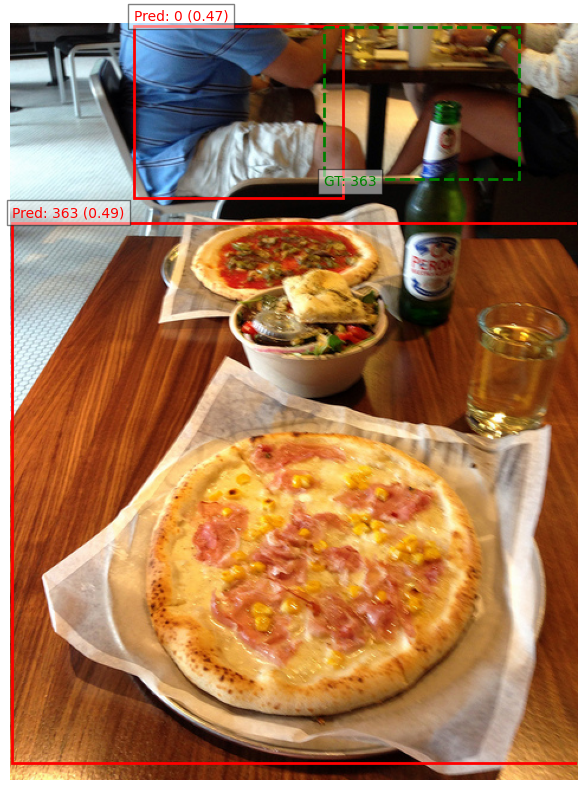

In [39]:
images_path = "../dataset/refl4/images"

test_images = ["COCO_train2014_000000080826.jpg", "COCO_train2014_000000276089.jpg",
               "COCO_train2014_000000544294.jpg", "objects365_v2_00956912.jpg", "objects365_v2_01697815.jpg"]

for test_image in test_images:
    show_image_prediction(config,
                          model,                        #
                          subset_dataset,               # Dataset to search for the image
                          0.9,                          # Iou score to consider outputting the box
                          test_image, # Image filename
                          images_path,
                          with_images = True,          # Whether the input to the model is supposed to be images
                          all_boxes = False)            # Whether to output all bounding boxes or only correctly predicted classes and overlapping ones